# Basisrente: What the Contract Yields, and the Same Money in an ETF

A real contract, modelled month by month: the NÜRNBERGER Fondsgebundene
Basisrente (tariff NFX3208T) signed in October 2024 — 500 € a month from
November 2024, 468 contributions, a lifelong pension from 1 November 2063, at
67. The documents stay out of git (`data/ruerp/`); the figures used here are
copied from them and pinned in
[`tests/test_ruerup.py`](../tests/test_ruerup.py), where the model reproduces
the insurer's year-by-year contract values to within 20 € in the early years
and 0.015% after four decades.

Three questions:

1. **What does the contract yield?** Capital and pension at 67 across market
   returns, the guaranteed annuity factor against the current one, and where
   the costs go.
2. **Rürup against an ETF.** Two worlds with the same gross outlay: the
   contract, with its tax refunds invested, or the same 500 € a month in a
   broad ETF. At 67 the ETF world holds more liquid capital and the Rürup
   world a pension for life. The *break-even age* is when that extra ETF
   capital, paying out exactly the Rürup's net pension, would run dry —
   beyond it the Rürup wins, before it the ETF does.
3. **How much to contribute?** A top-up from 2026, booked as a second contract
   the way the insurer books an Erhöhung, from 250 € a month to the
   deduction cap and beyond.

These are model results under stated assumptions, not advice: they move with
the market return, the tax rate in old age and how long one lives.

In [1]:
from pathlib import Path
import sys

ROOT_DIR = Path.cwd().resolve().parent
sys.path.append(str(ROOT_DIR))

import pandas as pd
from matplotlib import pyplot as plt

from src.model import (
    Earner,
    Etf,
    FinancialModel,
    GermanHousehold,
    PrivateHealthInsurance,
    RuerupAnnuity,
    RuerupCosts,
    RuerupPension,
)
from src.model.components.etf import sell
from src.model.german_tax import (
    TaxSystem,
    assessed_tax,
    basisrente_cap,
    social_contributions,
    taxable_income,
)

## Assumptions

**The contract** (signed version): 500 € a month for 468 months, 14 of them
paid before the model starts in January 2026. The tariff's own costs —
2.5% acquisition cost on the 234,000 € contribution sum spread over five
years, 4.5% of every contribution, 0.40% a year on the capital — are the
`RuerupCosts` defaults. The five funds cost about 0.38% a year on top: that is
what reconciles the tariff with the PIB's gross-return examples.

**The pension**: the guaranteed Rentenfaktor is 21.246830 € a month per
10,000 €. The insurer illustrates 24.996271 € (its 2024 basis) plus a
Zusatzrente of 1.87% of the capital a year — nearly twice the guarantee, and
neither part promised.

**The ETF**: a broad world ETF at 0.20% TER, taxed at the Abgeltungsteuer
with Soli on 70% of the gain (Teilfreistellung). The Sparerpauschbetrag and
the Vorabpauschale are left out. Both products see the same market return,
each less its own fund costs.

**Placeholders** until the documents arrive: the second salary (80,000 €
with statutory insurance, as in the insurer's tax illustration), and the
statutory pensions (the insurer's own estimate, turned back into
Entgeltpunkte and valued at today's Rentenwert).

In [2]:
SYSTEM = TaxSystem()                # 2026 law, drifting by inertia
MONTHLY = 500.0
TERM = 468                          # contributions Nov 2024 – Oct 2063
ELAPSED = 14                        # paid before the model starts in January 2026
START_AGE = 67

GUARANTEED = RuerupAnnuity()                                   # 21.246830 € per 10,000 €
DECLARED = RuerupAnnuity(factor=24.996271, bonus_rate=0.0187)  # 2024 basis, not promised

FUND_COSTS = 0.0038                 # the five funds' own costs
ETF_TER = 0.0020
ETF_TAX = 0.26375 * 0.7             # Abgeltungsteuer + Soli with 30% Teilfreistellung
INFLATION = 0.02
WAGE_GROWTH = SYSTEM.yearly_wage_growth   # salaries, and the statutory pensions after them

# The insurer's estimate: 9,882 € and 8,524 € a month in 2063 at its
# fictitious Rentenwert of 124.53 € — in Entgeltpunkte, at today's 40.79 €.
STATUTORY_MONTHLY = (9_882 + 8_524) / 124.53 * 40.79


def fund_return(market: float, costs: float) -> float:
    # A fund's own growth: the market return less the fund's costs.
    return (1.0 + market) * (1.0 - costs) - 1.0


def contract(market: float, **changes) -> RuerupPension:
    return RuerupPension(
        monthly_contribution=MONTHLY,
        contribution_months=TERM,
        yearly_return_rate=fund_return(market, FUND_COSTS),
        **changes,
    )


print(f"Statutory pensions, both of you, in today's money: €{STATUTORY_MONTHLY:,.0f} a month")

Statutory pensions, both of you, in today's money: €6,029 a month


## 1. What the Contract Yields

First the model against the insurer. The signed contract tabulates its value
at every anniversary for a fund growth — after the funds' costs — of 0, 3, 7
and 9% a year; a few of those years, insurer against model:

In [3]:
INSURER = {  # contract value at the anniversary, from the signed contract
    0.00: {1: 4_549, 5: 22_570, 10: 50_493, 20: 104_691, 30: 156_764, 39: 201_881},
    0.03: {1: 4_611, 5: 24_288, 10: 58_127, 20: 140_273, 30: 246_341, 39: 367_974},
    0.07: {1: 4_693, 5: 26_767, 10: 70_443, 20: 213_037, 30: 482_541, 39: 925_194},
    0.09: {1: 4_733, 5: 28_092, 10: 77_678, 20: 265_247, 30: 691_876, 39: 1_525_634},
}

table = {}
worst = 0.0
for growth, values in INSURER.items():
    model = RuerupPension(
        monthly_contribution=MONTHLY, contribution_months=TERM, yearly_return_rate=growth
    ).contract_values()
    column = {}
    for year, insurer in values.items():
        ours = model[12 * year - 1]
        worst = max(worst, abs(ours / insurer - 1.0))
        column[year] = f"€{insurer:>9,} / €{ours:>9,.0f}"
    table[f"{growth:.0%} (insurer / model)"] = column
print(f"Largest deviation in this table: {worst * 100:.3f}%")
pd.DataFrame(table).rename_axis("year")

Largest deviation in this table: 0.071%


,0% (insurer / model),3% (insurer / model),7% (insurer / model),9% (insurer / model)
year,,,,
1,"€ 4,549 / € 4,552","€ 4,611 / € 4,614","€ 4,693 / € 4,696","€ 4,733 / € 4,736"
5,"€ 22,570 / € 22,577","€ 24,288 / € 24,295","€ 26,767 / € 26,775","€ 28,092 / € 28,101"
10,"€ 50,493 / € 50,500","€ 58,127 / € 58,135","€ 70,443 / € 70,455","€ 77,678 / € 77,691"
20,"€ 104,691 / € 104,698","€ 140,273 / € 140,284","€ 213,037 / € 213,059","€ 265,247 / € 265,276"
30,"€ 156,764 / € 156,770","€ 246,341 / € 246,355","€ 482,541 / € 482,581","€ 691,876 / € 691,942"
39,"€ 201,881 / € 201,887","€ 367,974 / € 367,991","€ 925,194 / € 925,264","€1,525,634 / €1,525,773"


Now with a market return instead of a fund growth: the five funds keep 0.38% a
year for themselves before the tariff's costs start. The pension starts in
November 2063; "today's money" deflates it by 2% a year back to 2026.

In [4]:
YEARS_TO_PENSION = (TERM - ELAPSED) / 12
DEFLATOR = (1.0 + INFLATION) ** YEARS_TO_PENSION

rows = []
for market in (0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08):
    capital = contract(market).capital_at_pension_start()
    declared = DECLARED.monthly_pension(capital)
    rows.append(
        {
            "market return": f"{market:.0%}",
            "capital at 67": f"€{capital:,.0f}",
            "pension, guaranteed": f"€{GUARANTEED.monthly_pension(capital):,.0f}",
            "pension, 2024 basis": f"€{declared:,.0f}",
            "2024 basis, today's €": f"€{declared / DEFLATOR:,.0f}",
        }
    )
pd.DataFrame(rows)

,market return,capital at 67,"pension, guaranteed","pension, 2024 basis","2024 basis, today's €"
0,2%,"€276,104",€587,"€1,120",€530
1,3%,"€339,331",€721,"€1,377",€651
2,4%,"€420,864",€894,"€1,708",€807
3,5%,"€526,447","€1,119","€2,136","€1,010"
4,6%,"€663,669","€1,410","€2,693","€1,273"
5,7%,"€842,570","€1,790","€3,419","€1,616"
6,8%,"€1,076,425","€2,287","€4,368","€2,065"


### Where the costs go

At a 5% market return, starting from a contract that cost nothing and adding
one cost layer at a time. Each figure is what that layer takes from the
capital at 67, compounded — larger than the euros it charges, because a euro
charged early would have kept growing.

In [5]:
MARKET = 0.05


def capital_with(costs: RuerupCosts, fund_costs: float) -> float:
    return RuerupPension(
        monthly_contribution=MONTHLY,
        contribution_months=TERM,
        yearly_return_rate=fund_return(MARKET, fund_costs),
        costs=costs,
    ).capital_at_pension_start()


steps = [
    ("no costs at all", capital_with(RuerupCosts(0.0, 60, 0.0, 0.0), 0.0)),
    ("+ 2.5% acquisition cost, over 5 years", capital_with(RuerupCosts(0.025, 60, 0.0, 0.0), 0.0)),
    ("+ 4.5% of every contribution", capital_with(RuerupCosts(0.025, 60, 0.045, 0.0), 0.0)),
    ("+ 0.40% a year on the capital", capital_with(RuerupCosts(), 0.0)),
    ("+ the funds' own 0.38% a year", capital_with(RuerupCosts(), FUND_COSTS)),
]
pd.DataFrame(
    [
        {
            "": label,
            "capital at 67": f"€{value:,.0f}",
            "this layer takes": "" if index == 0 else f"€{steps[index - 1][1] - value:,.0f}",
        }
        for index, (label, value) in enumerate(steps)
    ]
)

,,capital at 67,this layer takes
0,no costs at all,"€702,972",
1,"+ 2.5% acquisition cost, over 5 years","€668,097","€34,876"
2,+ 4.5% of every contribution,"€636,463","€31,634"
3,+ 0.40% a year on the capital,"€577,109","€59,354"
4,+ the funds' own 0.38% a year,"€526,447","€50,662"


In [6]:
def effective_return(capital: float) -> float:
    # The yearly return that turns the contributions into `capital` with no cost at all.
    low, high = -0.05, 0.20
    for _ in range(100):
        guess = (low + high) / 2.0
        rate = (1.0 + guess) ** (1.0 / 12.0) - 1.0
        value = 0.0
        for _ in range(TERM):
            value = value * (1.0 + rate) + MONTHLY
        value *= 1.0 + rate
        low, high = (guess, high) if value < capital else (low, guess)
    return guess


after_costs = effective_return(steps[-1][1])
print(f"Paid in over 39 years:   €{MONTHLY * TERM:,.0f}")
print(f"Capital at 67, at {MARKET:.0%}:   €{steps[-1][1]:,.0f}")
print(f"Effective return:        {after_costs * 100:.2f}% a year, "
      f"{(MARKET - after_costs) * 100:.2f} points of costs (the PIB states 1.23)")

Paid in over 39 years:   €234,000
Capital at 67, at 5%:   €526,447
Effective return:        3.78% a year, 1.22 points of costs (the PIB states 1.23)


## 2. Rürup against an ETF

The same household in two worlds, with the same gross outlay. In one it pays
500 € a month into the contract; the tax that saves comes back every July and
goes into the ETF. In the other the 500 € go straight into the ETF. You earn
100,000 € and are privately insured (the May 2026 payslip); your spouse earns
80,000 € with statutory insurance (the placeholder). Both salaries grow with
wages; Steuerklasse IV/IV. Everything else is shared and cancels out.

This is a comparison of the product, so both worlds start with the contract,
39 years before the pension. The calendar is shifted by 14 months, which lets
2026 law apply from the first year.

At 67 the ETF world holds more liquid capital. From then on it pays itself
exactly the Rürup's net pension — gross pension less the extra income tax it
costs in old age, on top of the statutory pensions — and pays the ETF's own
tax on every withdrawal. The age at which that capital runs dry is the
break-even age.

In [7]:
YEARS = TERM // 12
RETIREMENT_LAW = TaxSystem(rich_threshold_frozen=False)  # no 50-year freeze of the 45% border


def household() -> GermanHousehold:
    return GermanHousehold(
        earners=(
            Earner(
                monthly_gross=100_000 / 12,
                yearly_increase_rate=WAGE_GROWTH,
                private_health=PrivateHealthInsurance(
                    monthly_premium=638.0,
                    monthly_care_premium=57.0,
                    deductible_share=349.0 / 638.0,
                    monthly_rebate=182.95,
                ),
            ),
            Earner(monthly_gross=80_000 / 12, yearly_increase_rate=WAGE_GROWTH),
        ),
        tax_classes="IV/IV",
    )


def etf(market: float) -> Etf:
    return Etf(yearly_return_rate=fund_return(market, ETF_TER), tax_rate=ETF_TAX)


def gap(with_contract: pd.DataFrame, without: pd.DataFrame, year: int) -> tuple[float, float]:
    # What the ETF world holds more at the end of `year`, as capital and cost
    # basis. The engine drops the last year's tax settlement beyond its
    # horizon, so the contract world's pending refund is added back as cash.
    pending = (
        without.loc[year, "household.yearly_assessed_tax"]
        - with_contract.loc[year, "household.yearly_assessed_tax"]
    )
    capital = without.loc[year, "etf_capital"] - with_contract.loc[year, "etf_capital"] - pending
    basis = without.loc[year, "etf_cost_basis"] - with_contract.loc[year, "etf_cost_basis"] - pending
    return capital, basis


def retirement_tax(pension_yearly, year_index, *, statutory=STATUTORY_MONTHLY,
                   other_yearly=0.0, law=RETIREMENT_LAW):
    # The extra income tax a pension costs the couple in a retirement year.
    system = law.for_year(year_index)
    base = statutory * 12.0 * (1.0 + WAGE_GROWTH) ** year_index + other_yearly

    def tax(pensions: float) -> float:
        zve = taxable_income([], system, joint=True, pension_income=pensions)
        return assessed_tax(zve, system, joint=True, n_children=0).total

    return tax(base + pension_yearly) - tax(base)


def drawdown(capital, basis, pension, year_index, market, **tax_options):
    # The extra ETF capital paying the pension's net amount, year by year to
    # age 100. Returns the year-end balances and the age it runs dry, or None.
    rate = (1.0 + fund_return(market, ETF_TER)) ** (1.0 / 12.0) - 1.0
    balances = [capital]
    for month in range(12 * (100 - START_AGE)):
        if month % 12 == 0:
            tax = retirement_tax(12.0 * pension, year_index + month // 12, **tax_options)
            net = pension - tax / 12.0
        capital *= 1.0 + rate
        gross = net / (1.0 - max(0.0, 1.0 - basis / capital) * ETF_TAX)
        if capital < gross:
            balances.append(0.0)
            return balances, START_AGE + (month + capital / gross) / 12.0
        basis = sell(capital, basis, gross)
        capital -= gross
        if month % 12 == 11:
            balances.append(capital)
    return balances, None


def age(value) -> str:
    return "after 100" if value is None else f"{value:.1f}"

In [8]:
worlds = {}
rows = []
for market in (0.03, 0.05, 0.07):
    with_contract = FinancialModel([household(), contract(market), etf(market)], years=YEARS).run()
    without = FinancialModel([household(), etf(market)], years=YEARS).run()
    capital, basis = gap(with_contract, without, YEARS)
    refunds = (
        without["household.yearly_assessed_tax"] - with_contract["household.yearly_assessed_tax"]
    ).sum()
    pension_capital = contract(market).capital_at_pension_start()
    worlds[market] = (capital, basis, pension_capital)
    row = {
        "market return": f"{market:.0%}",
        "tax refunds": f"€{refunds:,.0f} ({refunds / (MONTHLY * TERM):.0%})",
        "Rürup capital at 67": f"€{pension_capital:,.0f}",
        "extra ETF capital at 67": f"€{capital:,.0f}",
    }
    for label, annuity in (("guaranteed", GUARANTEED), ("2024 basis", DECLARED)):
        pension = annuity.monthly_pension(pension_capital)
        net = pension - retirement_tax(12.0 * pension, YEARS) / 12.0
        row[f"net pension, {label}"] = f"€{net:,.0f}"
        row[f"break-even, {label}"] = age(drawdown(capital, basis, pension, YEARS, market)[1])
    rows.append(row)
pd.DataFrame(rows).set_index("market return").T

market return,3%,5%,7%
tax refunds,"€109,461 (47%)","€109,461 (47%)","€109,461 (47%)"
Rürup capital at 67,"€339,331","€526,447","€842,570"
extra ETF capital at 67,"€229,326","€370,514","€616,413"
"net pension, guaranteed",€468,€725,"€1,156"
"break-even, guaranteed",after 100,after 100,after 100
"net pension, 2024 basis",€891,"€1,376","€2,185"
"break-even, 2024 basis",95.1,after 100,after 100


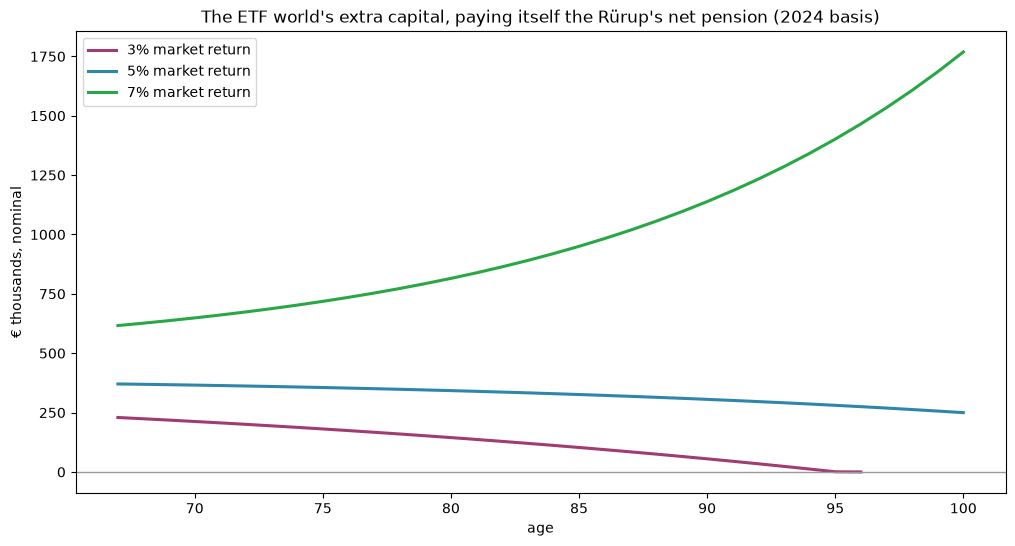

In [9]:
fig, ax = plt.subplots(figsize=(12, 6))
for market, color in ((0.03, "#A23B72"), (0.05, "#2E86AB"), (0.07, "#28A745")):
    capital, basis, pension_capital = worlds[market]
    pension = DECLARED.monthly_pension(pension_capital)
    balances, _ = drawdown(capital, basis, pension, YEARS, market)
    ages = [START_AGE + index for index in range(len(balances))]
    ax.plot(ages, [b / 1000 for b in balances], color=color, lw=2.2,
            label=f"{market:.0%} market return")
ax.axhline(0, color="#999999", lw=1)
ax.set_title("The ETF world's extra capital, paying itself the Rürup's net pension (2024 basis)")
ax.set_xlabel("age")
ax.set_ylabel("€ thousands, nominal")
ax.legend()
plt.show()

### What moves the break-even age

The tax in old age is the least certain input. It depends on how large the
statutory pensions turn out to be, and on whether the tariff keeps up with
pensions: the inertia behind `TaxSystem` lets wages, and the pensions after
them, grow at 3.3% while the tariff borders move at 2.5%. Over four decades
that creep alone puts the pension into a higher bracket. Below, the
statutory pensions at the placeholder and at half of it, with the tariff
either creeping or moving with wages — the 2024 annuity basis throughout.

In [10]:
indexed = TaxSystem(rich_threshold_frozen=False, yearly_threshold_growth=WAGE_GROWTH)
rows = []
for statutory_share in (1.0, 0.5):
    for law_label, law in (("tariff creeps (2.5%)", RETIREMENT_LAW), ("tariff moves with wages", indexed)):
        row = {"statutory pensions": f"{statutory_share:.0%} of placeholder", "tariff": law_label}
        for market, (capital, basis, pension_capital) in worlds.items():
            pension = DECLARED.monthly_pension(pension_capital)
            options = dict(statutory=STATUTORY_MONTHLY * statutory_share, law=law)
            tax_share = retirement_tax(12.0 * pension, YEARS, **options) / (12.0 * pension)
            reached = drawdown(capital, basis, pension, YEARS, market, **options)[1]
            row[f"{market:.0%}: tax / break-even"] = f"{tax_share:.0%} / {age(reached)}"
        rows.append(row)
pd.DataFrame(rows)

,statutory pensions,tariff,3%: tax / break-even,5%: tax / break-even,7%: tax / break-even
0,100% of placeholder,tariff creeps (2.5%),35% / 95.1,36% / after 100,36% / after 100
1,100% of placeholder,tariff moves with wages,31% / 91.5,31% / after 100,31% / after 100
2,50% of placeholder,tariff creeps (2.5%),27% / 90.1,27% / after 100,28% / after 100
3,50% of placeholder,tariff moves with wages,24% / 88.8,25% / 98.0,25% / after 100


## 3. How Much to Contribute

Now on the real calendar: the contract is already running in both worlds, and
the question is a top-up from January 2026 to the end. The insurer books an
Erhöhung as a part of its own, with its own 2.5% acquisition cost on its own
contribution sum, ending with the main contract — so here it is a second
`RuerupPension`, starting at month zero and running the remaining 454 months.

The deduction cap is shared: 61,652 € for the couple in 2026, less both halves
of both statutory contributions, less the 6,000 € the contract already uses.
Above that a contribution saves nothing at all. Below it, every euro saves less
than the one before, because each pushes the taxable income down the tariff.

The comparison stops at the end of 2063. That December already holds two
months of pension, taxed on top of the salaries the household never stops
earning, but the difference is small next to the four decades before it. In
old age the top-up's pension is taxed on top of the statutory pensions *and*
the main contract's.

In [11]:
REMAINING = TERM - ELAPSED   # January 2026 – October 2063
REAL_YEARS = 38              # the year-38 row is December 2063

room = basisrente_cap(SYSTEM, joint=True) - 12.0 * MONTHLY
for gross, private in ((100_000.0, True), (80_000.0, False)):
    social = social_contributions(gross, SYSTEM, n_children=0, private_health=private)
    room -= 2.0 * social.pension
print(f"Deduction room left in 2026: €{room:,.0f} a year, €{room / 12:,.0f} a month")

markets = {}
for market in (0.03, 0.05):
    base = [household(), contract(market, elapsed_months=ELAPSED), etf(market)]
    main_pension = DECLARED.monthly_pension(contract(market).capital_at_pension_start())
    markets[market] = (base, FinancialModel(base, years=REAL_YEARS).run(), main_pension)

rows = []
for top_up in (250, 500, 1_000, 1_500, round(room / 12), 2_500):
    row = {"top-up / month": f"€{top_up:,}"}
    for market, (base, without, main_pension) in markets.items():
        extra = RuerupPension(
            monthly_contribution=float(top_up),
            contribution_months=REMAINING,
            yearly_return_rate=fund_return(market, FUND_COSTS),
            name="top_up",
        )
        with_top_up = FinancialModel([*base, extra], years=REAL_YEARS).run()
        saved = (
            without.loc[1, "household.yearly_assessed_tax"]
            - with_top_up.loc[1, "household.yearly_assessed_tax"]
        )
        row["tax saved in 2026, per €"] = f"{saved / (12.0 * top_up):.1%}"
        capital, basis = gap(with_top_up, without, REAL_YEARS)
        pension = DECLARED.monthly_pension(extra.capital_at_pension_start())
        reached = drawdown(capital, basis, pension, REAL_YEARS, market,
                           other_yearly=12.0 * main_pension)[1]
        row[f"{market:.0%}: pension"] = f"€{pension:,.0f}"
        row[f"{market:.0%}: extra ETF at 67"] = f"€{capital:,.0f}"
        row[f"{market:.0%}: break-even"] = age(reached)
    rows.append(row)
pd.DataFrame(rows).set_index("top-up / month")

Deduction room left in 2026: €22,172 a year, €1,848 a month


,"tax saved in 2026, per €",3%: pension,3%: extra ETF at 67,3%: break-even,5%: pension,5%: extra ETF at 67,5%: break-even
top-up / month,,,,,,,
€250,42.0%,€659,"€110,448",95.7,"€1,007","€176,534",after 100
€500,42.0%,"€1,317","€221,536",96.0,"€2,013","€354,241",after 100
"€1,000",41.7%,"€2,634","€445,466",96.5,"€4,026","€712,769",after 100
"€1,500",41.3%,"€3,952","€671,822",97.1,"€6,039","€1,075,536",after 100
"€1,848",40.9%,"€4,868","€830,789",97.5,"€7,440","€1,330,480",after 100
"€2,500",30.2%,"€6,586","€1,166,855",99.7,"€10,065","€1,881,252",after 100


## What This Leaves Out

- The household never retires in the engine; old age is priced with the pure
  tariff on the statutory pensions plus the Rürup, without the health and care
  contributions a retiree deducts (which would lower that tax a little).
- No Rentengarantiezeit: a death before 87 would pay the remaining guaranteed
  months to a surviving spouse, while the ETF world would leave its whole
  remaining capital.
- The pension stays flat; above a 3% Gesamtverzinsung the insurer would raise it
  a little each year.
- Returns are smooth. With volatile ones the kursorientiertes
  Ablaufmanagement in the contract would matter, and so would the order of
  good and bad years.
- The placeholders: the second salary and both statutory pensions. Once the
  Renteninformation and the second payslip are in `data/ruerp/`, replace them.